# Lets clean the Titanic Datasets
**Jesca**
*The titanic sunk in 1912 and killed 1500 people*

# Method 1: Label Encoding

## **1.Importing required libraries**
This cell is for importing usefull libraries that we are going to use to clean the titanic
The as just gives the libraries a short form

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Loading the datasets
This loads the titanic datasets and tells pandas to read the file with the name Titanic-Dataser.csv and converts the rows and columns into a formart python understands

In [2]:
df_titanic=pd.read_csv('Titanic-Dataset.csv')

## 3.Previeving our datasets
This code shows the first five rows on my titanic datasets in the csv file

In [3]:
df_titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 4.Checking Datatype and the Structure
This give a complete summary of the whole titanic datasets, it gives the total rows and columns, the mising data and the number of filled data and also the datatype of each column

In [4]:
df_titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


## 5. Filling missing Ages for Master passengers
This cell finds all young boys with the title master in their name in the Titanic dataset. It calculates their average age and uses that average to fill in any missing age values for those specific passengers.


In [5]:
mask = df_titanic["Name"].str.contains("Master", na=False)
master_age_mean=df_titanic.loc[mask, "Age"].mean()
df_titanic.loc[mask, "Age"] =df_titanic.loc[mask, "Age"].fillna(master_age_mean)

## 6. Filling missing Ages for Miss passengers
This cell identifies all unmarried female passengers those with the title "Miss" in their name. It calculates the average age for this group and uses that specific average to fill in any of their missing age values.

In [6]:
mask_miss = df_titanic["Name"].str.contains("Miss", na=False)
miss_age_mean = df_titanic.loc[mask_miss, "Age"].mean()
df_titanic.loc[mask_miss, "Age"] = df_titanic.loc[mask_miss, "Age"].fillna(miss_age_mean)


## 7. Filling missing Ages for Mrs passengers
This cell finds all married female passengers those with the title "Mrs" in their name. It calculates the average age for this specific group and uses it to fill in any of their missing age values.

In [7]:
mask_mrs = df_titanic["Name"].str.contains("Mrs", na=False)
mrs_age_mean = df_titanic.loc[mask_mrs, "Age"].mean()
df_titanic.loc[mask_mrs, "Age"] = df_titanic.loc[mask_mrs, "Age"].fillna(mrs_age_mean)

## 8. Filling missing Ages for Mr passengers
This cell finds adult male passengers those with the title "Mr." in their name. It excludes "Mrs." passengers from the search, calculates the average age for the men, and fills in their missing age values.


In [8]:
mask_mr = df_titanic["Name"].str.contains("Mr\.", na=False) 
mr_age_mean = df_titanic.loc[mask_mr, "Age"].mean()
df_titanic.loc[mask_mr, "Age"] = df_titanic.loc[mask_mr, "Age"].fillna(mr_age_mean)

## 9. Fixing empty embarked rows
This cell specifically targets the passenger "Icard, Miss. Amelie" to fill in her missing Embarked value. Based on historical data, she boarded the Titanic at Southampton, so her missing value is manually set to 'S'.

In [9]:
mask = df_titanic['Name'].str.contains('Icard, Miss. Amelie', na=False)
df_titanic.loc[mask, 'Embarked'] = 'S'

## 10. Fixing empty embarked rows
This cell targets the passenger "Stone, Mrs. George Nelson" to fill in her missing Embarked value.She also boarded the Titanic at Southampton, so her record is manually set to 'S'.

In [10]:
mask_stone = df_titanic['Name'].str.contains('Stone, Mrs. George Nelson', na=False)
df_titanic.loc[mask_stone, 'Embarked'] = 'S'

## 11. Creating a dataset X
This code creates a copy of the csv file and only removes the survived columns which is the vertical column 1.

In [11]:
X = df_titanic.drop(['Survived'],axis=1)

## 12. Dropping Columns
This cell removes the Cabin column entirely from the dataset. This column is dropped because it contains too many missing values hence it is not very useful for our analysis.
The passengerid doesn't contain any useful pattern we can use to predict survival

In [12]:
X = X.drop(['Name', 'Ticket', 'Cabin', 'PassengerId'], axis=1)

## 13. Target Variable y
This code cell takes only the survived column and saves it as a separate file called y

In [13]:
y=df_titanic['Survived']

## 14. Previewing X
This cell gives you the first five rows in the x file

In [14]:
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


## 15. Previewing y 
This cell gives you the first five rows in the y file

In [15]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

## 16. Visualizing the target class distribution
This cell counts how many passengers survived versus how many did not. It then plots these counts as a bar chart so we can visually check if our target variable is balanced.

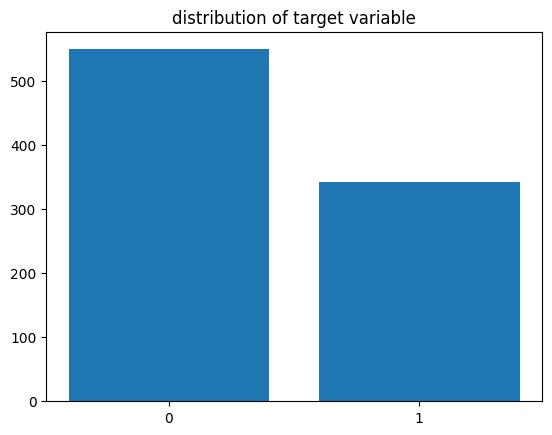

In [16]:
x=y.value_counts()
plt.bar(x.index,x)
plt.gca().set_xticks([0,1])
plt.title('distribution of target variable')
plt.show()

## 17. Importing Machine Learning Libraries
This cell imports the necessary tools from scikit-learn to prepare our data and build our model. This includes tools for label encoding, splitting our data into training and testing sets, running a Logistic Regression model, and measuring the final accuracy score.

In [17]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn import base

## 18. Apllication of label encoding
This cell finds every text column/object data type in our X features and applies Label Encoding to convert it into numbers.

In [18]:
train = pd.DataFrame()
label = LabelEncoder()

for c in X.columns:         
    if X[c].dtype == 'object':
        train[c] = label.fit_transform(X[c])
    else:
        train[c] = X[c]

## 19. Final check
This cell finds any remaining missing values in our train dataset and replaces them with the average value of their respective columns, ensuring the model won't crash during training.

In [19]:
train = train.fillna(train.mean())

## 20. Training a logistic regression model
This cell builds a custom function to test how well a Logistic Regression model can predict passenger survival. It automates splitting the data, training the algorithm on a 80% training chunk, making predictions on the remaining 20% test chunk, and instantly printing out the final correctness percentage.

In [20]:
def logistic(X, y):
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42, test_size=0.2)
    lr = LogisticRegression(max_iter=1000)
    lr.fit(X_train, y_train)
    y_pre = lr.predict(X_test)
    print('Accuracy : ', accuracy_score(y_test, y_pre))

## 21. Running the Logistic Regression Model
This cell calls our custom function using our fully prepared features (train) and our target variable (y) to train the model and see our final prediction accuracy.

In [21]:
logistic(train, y)

Accuracy :  0.8100558659217877


# Method 2: On Hot Encoding

## 1. One-Hot Encoding with pd.get_dummies()

We use pandas get_dummies() to convert categorical columns (Sex, Embarked) into binary columns.

In [22]:
X_encoded = pd.get_dummies(X, columns=['Sex', 'Embarked'], drop_first=True)

## 2. Any Remaining columns
This cell finds any remaining missing values in our train dataset and replaces them with the average value of their respective columns, ensuring the model won't crash during training.

In [23]:
X_encoded = X_encoded.fillna(X_encoded.mean())

## 3. Convertion
This cell converts to integers for cleaner output

In [24]:
X_encoded = X_encoded.astype(np.int8)

## 4. Previewing X_encoded
This cell gives you the first five rows in the x_encoded file

In [25]:
X_encoded.head()

,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,3,22,1,0,7,1,0,1
1,1,38,1,0,71,0,0,0
2,3,26,0,0,7,0,0,1
3,1,35,1,0,53,0,0,1
4,3,35,0,0,8,1,0,1


## 5. Training the Logistic Regression Model

This cell splits the encoded data into training and testing sets, then train and evaluate the model.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, random_state=42, test_size=0.2)

lr = LogisticRegression(max_iter=1000)

lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)

print('Accuracy:', accuracy_score(y_test, y_pred))

Accuracy: 0.8156424581005587
